#### Пересечение луча и сферы
##### Луч из точки $\vec{r}_0$ в направлении $\vec{d}$ $$\vec{r}(t) = \vec{r}_0 + t\cdot\vec{d}$$
##### Уравнение на принадлежность сфере радиусом $R$ с центром в $\vec{p}$ $$(\vec{r}(t) - \vec{p})^2 = R^2$$ $$(\vec{r}_0 - \vec{p} + t\cdot\vec{d})^2 = R^2 $$
##### $$t^2 + t\cdot 2((\vec{r}_0 - \vec{p}) , \vec{d}) + (\vec{r}_0 - \vec{p})^2 - R^2 = 0$$
##### Ищем только одно значение t, соответствующее направлению $\vec{d}$ $$t = -((\vec{r}_0 - \vec{p}) , \vec{d}) + \sqrt{((\vec{r}_0 - \vec{p}) , \vec{d})^2 - ((\vec{r}_0 - \vec{p})^2 - R^2)}$$

##### Частный случай: $(\vec{r}_0 - \vec{p}) = \vec{0} \rightarrow t = R$


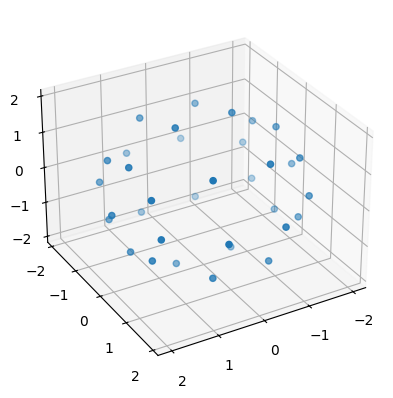

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipynb.fs.full.Detector import Detector
from ipynb.fs.full.Source import Source

def points_of_photons_intersection_with_sphere(source: Source, sphere_R: float, sphere_position: np.ndarray):
    """Function to find interstion of line and sphere points"""
    r0 = source.position
    d = source.directions
    p = sphere_position
    R2 = sphere_R**2

    scalar = d @ (r0-p)
    discriminant = scalar**2 - ((r0-p) @ (r0-p) - R2)
    mask = discriminant >= 0
    if not mask.any(): return np.empty((0, 3)) 
    t = -scalar[mask] + np.sqrt(discriminant[mask]) 
    return r0 + (d[mask].T * t).T # points of intersection with sphere 

def get_FWHM(hist, bins):
    """Function for getting full width at half maximum of distribution"""
    x = (bins[1:] + bins[:-1])/2
    y = hist
    i = np.argmax(y)
    yh = y[i] / 2
    def interp(j):
        return x[j] + (yh - y[j]) * (x[j+1] - x[j]) / (y[j+1] - y[j])
    kl = np.where((y[:i] - yh) * (y[1:i+1] - yh) <= 0)[0]
    kr = np.where((y[i:-1] - yh) * (y[i+1:] - yh) <= 0)[0]
    xl = interp(kl[-1])       if kl.size else np.nan
    xr = interp(i + kr[0])    if kr.size else np.nan
    return xr - xl, xl, xr

#### Запуск одного события с $E = 1\, МэВ$
##### Ожидаемый полный заряд $$Q = a \cdot Y\cdot N\cdot\frac{r^2}{R^2}$$

In [2]:
det = Detector(N=40, position=(0.,0.,0.))
source = Source(energy=1, position=(0.,0.,0.))

hits_photons = det.points_are_in_pm(points_of_photons_intersection_with_sphere(source, det.R, det.position)) # [om_id, n_photons in it]
hits_phe = det.make_charge(hits_photons) # [om_id, phe]
total_charge = hits_phe[:, 1].sum()
expected_charge = det.a * source.Y * det.N * det.r**2 / det.R**2
print(f"Собранный заряд в моделировании 1 события: {total_charge}\nОжидаемый заряд Q = {expected_charge:.1f}\nРазница {(total_charge - expected_charge):.1f}")

Собранный заряд в моделировании 1 события: 109
Ожидаемый заряд Q = 500.0
Разница -391.0


#### Сделаем 1000 событий при источнике в центре сферы детектора

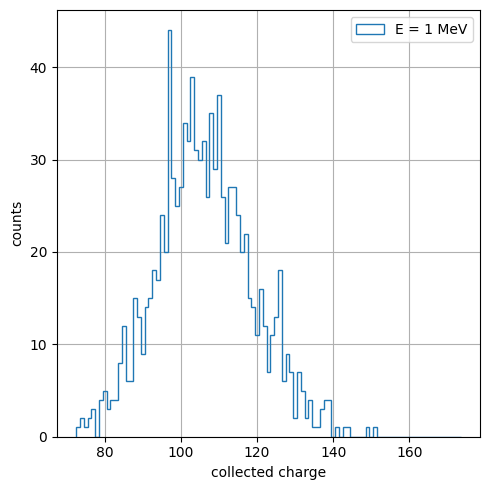

In [3]:
det = Detector(N=40, position=(0.,0.,0.))
N_events = 1000
total_charge = np.empty((N_events), dtype=np.int32)
for e in range(N_events):
    source = Source(energy=1, position=(0.,0.,0.))
    hits_photons = det.points_are_in_pm(points_of_photons_intersection_with_sphere(source, det.R, det.position)) # [om_id, n_photons in it]
    hits_phe = det.make_charge(hits_photons) # [om_id, phe]
    total_charge[e] = hits_phe[:, 1].sum()

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.hist(total_charge, bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', label="E = 1 MeV")
ax.set_xlabel("collected charge")
ax.set_ylabel("counts")
ax.grid()
ax.legend()
plt.tight_layout()

#### По 1000 событий для источника в цетре детектора, но с разными $E$

Calculating for 0.2 MeV
Calculating for 0.5 MeV
Calculating for 0.7 MeV
Calculating for 1.5 MeV
Calculating for 2.0 MeV
Calculating for 3.0 MeV


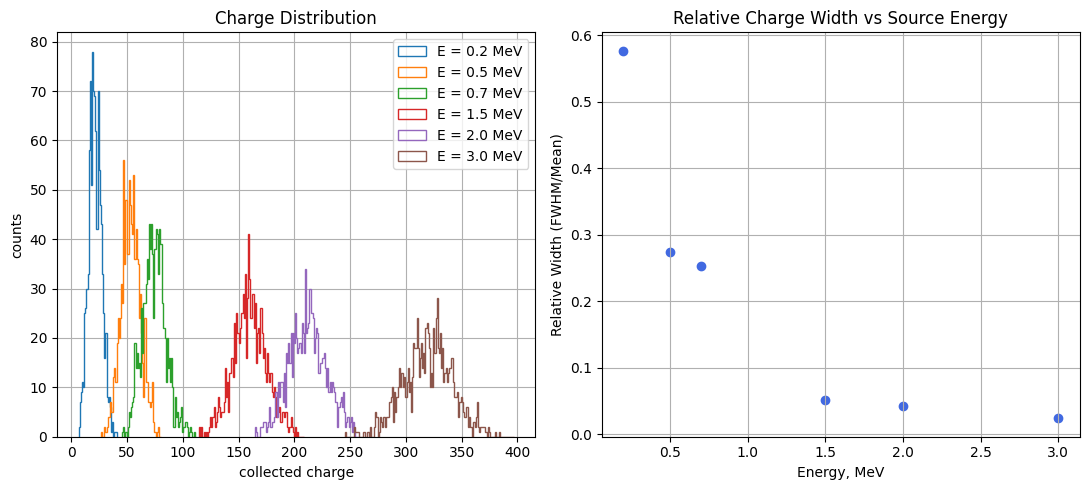

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5))

det = Detector(N=40, position=(0.,0.,0.))
Energies = (0.2, 0.5, 0.7, 1.5, 2.0, 3.0)
mean_charge_z0 = []
for E in Energies:
    print(f"Calculating for {E} MeV")
    N_events = 1000
    total_charge = np.empty((N_events), dtype=np.int32)
    for e in range(N_events):
        source = Source(energy=E, position=(0.,0.,0.))
        hits_photons = det.points_are_in_pm(points_of_photons_intersection_with_sphere(source, det.R, det.position)) # [om_id, n_photons in it]
        hits_phe = det.make_charge(hits_photons) # [om_id, phe]
        total_charge[e] = hits_phe[:, 1].sum()
    mean_charge_z0.append(total_charge.mean())
    histogram = axs[0].hist(total_charge, bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', label=f"E = {E} MeV")
    width, left_edge, right_edge = get_FWHM(histogram[0], histogram[1])
    axs[1].scatter(E, width/total_charge.mean(), color='royalblue')

axs[0].set_xlabel("collected charge")
axs[0].set_ylabel("counts")
axs[0].grid()
axs[0].legend()
axs[0].set_title("Charge Distribution")

axs[1].set_xlabel("Energy, MeV")
axs[1].set_ylabel("Relative Width (FWHM/Mean)")
axs[1].grid()
axs[1].set_title("Relative Charge Width vs Source Energy")
plt.tight_layout()

#### Теперь источник смещён на 1 метр по оси OZ

Calculating for 0.2 MeV
Calculating for 0.5 MeV
Calculating for 0.7 MeV
Calculating for 1.5 MeV
Calculating for 2.0 MeV
Calculating for 3.0 MeV


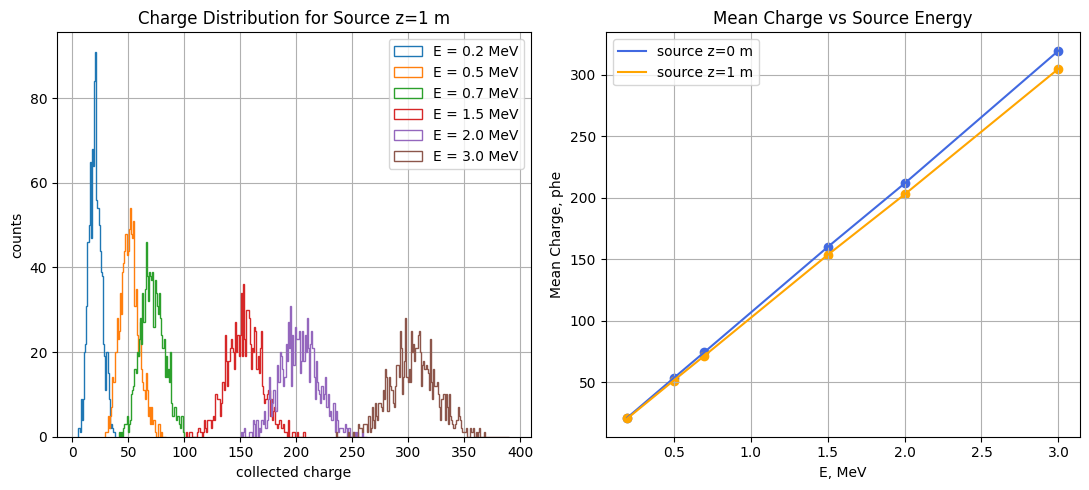

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5))

det = Detector(N=40, position=(0.,0.,0.))
Energies = (0.2, 0.5, 0.7, 1.5, 2.0, 3.0)
mean_charge_z1 = []
for E in Energies:
    print(f"Calculating for {E} MeV")
    N_events = 1000
    total_charge = np.empty((N_events), dtype=np.int32)
    for e in range(N_events):
        source = Source(energy=E, position=(0.,0.,1.))
        hits_photons = det.points_are_in_pm(points_of_photons_intersection_with_sphere(source, det.R, det.position)) # [om_id, n_photons in it]
        hits_phe = det.make_charge(hits_photons) # [om_id, phe]
        total_charge[e] = hits_phe[:, 1].sum()
    mean_charge_z1.append(total_charge.mean())
    axs[0].hist(total_charge, bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', label=f"E = {E} MeV")
axs[0].set_xlabel("collected charge")
axs[0].set_ylabel("counts")
axs[0].grid()
axs[0].legend()
axs[0].set_title("Charge Distribution for Source z=1 m")

axs[1].plot(Energies, mean_charge_z0, color="royalblue", label="source z=0 m")
axs[1].scatter(Energies, mean_charge_z0, color="royalblue")
axs[1].plot(Energies, mean_charge_z1, color="orange", label="source z=1 m")
axs[1].scatter(Energies, mean_charge_z1, color="orange")
axs[1].set_xlabel("E, MeV")
axs[1].set_ylabel("Mean Charge, phe")
axs[1].grid()
axs[1].legend()
axs[1].set_title("Mean Charge vs Source Energy")
plt.tight_layout()